# Visualisasi Dataset Lagu

Mata Kuliah: Data Mining

Nama: David Andrew Gregorius Tingang Liah

NIM: 2418058

Kelas: A

---

### Tujuan Data Visualization dalam Data Mining

Sebelum data dimodelkan atau dianalisis lebih jauh, data perlu "dilihat" dulu. Lewat grafik kita bisa cepat melihat sebaran nilai, pola, tren, hubungan antarvariabel, dan data yang terlihat janggal (outlier), yang sering tidak kelihatan kalau hanya membaca tabel angka.

### Dataset yang dipakai

Dataset ini adalah lanjutan dari dataset lagu yang saya pakai di tugas Data Cleansing. Seblumnya isinya 33 lagu, sekarang saya tambah menjadi 105 lagu. Data lama sudah bersih dari tugas sebelumnya, dan data baru saya susun dengan format yang sama. Nilai jumlah putar, popularitas, dan durasi adalah data contoh untuk latihan dan bukan angka resmi dari platform musik mana pun. Perlu dicatat juga bahwa beberapa nilai pada 33 lagu pertama adalah hasil pengisian median dari tugas Data Cleansing (misalnya popularitas Separuh Aku dan Umbrella, durasi Kangen dan Separuh Aku, serta jumlah putar Gangnam Style), karena nilai aslinya kosong atau tidak valid.

### Teknik visualisasi yang dipakai (Matplotlib dan Seaborn)

| No | Visualisasi | Tujuan |
|---|---|---|
| 1 | Line chart | melihat tren total jumlah putar per dekade |
| 2 | Bar chart | membandingkan jumlah lagu tiap genre |
| 3 | Histogram | melihat sebaran skor popularitas |
| 4 | Boxplot | membandingkan durasi lagu antargenre dan mencari outlier |
| 5 | Scatter plot | melihat hubungan jumlah putar dan popularitas |
| 6 | Heatmap | melihat korelasi antarvariabel numerik |
| 7 | Bar chart | membandingkan rata-rata popularitas antargenre |

Setiap grafik diberi judul, label sumbu, legenda, dan keterangan, lalu dilengkapi interpretasi. Di bagian akhir ada ringkasan insight dan kesimpulan.

## 1. Import Library dan Pengaturan Tampilan

In [ ]:
import io
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

# warna yang dipakai di semua grafik supaya tampilannya seragam
BIRU = '#2a78d6'
ORANYE = '#eb6834'
BIRU_MUDA = '#9ec5f4'
ABU = '#c3c2b7'
TEKS = '#0b0b0b'
TEKS_ABU = '#52514e'
GARIS_GRID = '#e4e3df'

# pengaturan umum grafik
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': ABU,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'text.color': TEKS,
    'axes.labelcolor': TEKS,
    'xtick.color': TEKS_ABU,
    'ytick.color': TEKS_ABU,
    'font.size': 11,
})

# folder untuk menyimpan gambar hasil visualisasi
os.makedirs('hasil_visualisasi', exist_ok=True)

## 2. Load Dataset

Data mentah saya tulis langsung di dalam notebook (sebagai teks CSV) supaya bisa dijalankan di Colab tanpa upload file. File yang sama juga ada di GitHub dengan nama dataset_musik_visualisasi.csv. Kalau mau baca dari file, tinggal ganti dengan pd.read_csv(dataset_musik_visualisasi.csv).

In [ ]:
data_teks = """id_lagu,judul,artis,genre,tahun_rilis,durasi_detik,jumlah_putar,popularitas,negara_artis,benua
1,Shape of You,Ed Sheeran,Pop,2017,233,3100000000,90,Britania Raya,Eropa
2,Blinding Lights,The Weeknd,Pop,2019,200,3400000000,92,Kanada,Amerika Utara
3,Bohemian Rhapsody,Queen,Rock,1975,355,2000000000,88,Britania Raya,Eropa
4,Someone Like You,Adele,Pop,2011,285,1700000000,80,Britania Raya,Eropa
5,Lose Yourself,Eminem,Hip-Hop,2002,326,2100000000,85,Amerika Serikat,Amerika Utara
6,Hotel California,Eagles,Rock,1976,390,1500000000,82,Amerika Serikat,Amerika Utara
7,Smells Like Teen Spirit,Nirvana,Rock,1991,301,1800000000,83,Amerika Serikat,Amerika Utara
8,Billie Jean,Michael Jackson,Pop,1983,294,1600000000,84,Amerika Serikat,Amerika Utara
9,Uptown Funk,Mark Ronson,Funk,2014,270,2300000000,81,Britania Raya,Eropa
10,Despacito,Luis Fonsi,Latin,2017,228,3000000000,78,Puerto Riko,Amerika Utara
11,Believer,Imagine Dragons,Rock,2017,204,2300000000,82,Amerika Serikat,Amerika Utara
12,Bad Guy,Billie Eilish,Pop,2019,194,2800000000,87,Amerika Serikat,Amerika Utara
13,Dynamite,BTS,K-Pop,2020,199,1400000000,82,Korea Selatan,Asia
14,Lathi,Weird Genius,EDM,2020,213,650000000,75,Indonesia,Asia
15,Hati-Hati di Jalan,Tulus,Pop,2022,250,520000000,74,Indonesia,Asia
16,Kangen,Dewa 19,Rock,1992,233,410000000,70,Indonesia,Asia
17,Yellow,Coldplay,Tidak Diketahui,2000,269,1900000000,84,Britania Raya,Eropa
18,Shake It Off,Taylor Swift,Pop,2014,219,2000000000,86,Amerika Serikat,Amerika Utara
19,Just the Way You Are,Bruno Mars,Pop,2010,220,1800000000,82,Amerika Serikat,Amerika Utara
20,Levitating,Dua Lipa,Pop,2020,203,2500000000,88,Britania Raya,Eropa
21,As It Was,Harry Styles,Pop,2022,157,3300000000,91,Britania Raya,Eropa
22,Umbrella,Rihanna,Pop,2007,276,1500000000,82,Barbados,Amerika Utara
23,Sunday Morning,Maroon 5,Pop,2004,241,1100000000,76,Amerika Serikat,Amerika Utara
24,In the End,Linkin Park,Rock,2001,216,1900000000,83,Amerika Serikat,Amerika Utara
25,Creep,Radiohead,Rock,1992,238,1400000000,78,Britania Raya,Eropa
26,Sephia,Sheila on 7,Pop,1999,243,380000000,68,Indonesia,Asia
27,Dancing Queen,ABBA,Disco,1976,231,1500000000,80,Swedia,Eropa
28,Wake Me Up,Avicii,EDM,2013,247,1800000000,82,Swedia,Eropa
29,Get Lucky,Daft Punk,Disco,2013,369,1800000000,79,Prancis,Eropa
30,Gangnam Style,PSY,K-Pop,2012,219,1800000000,77,Korea Selatan,Asia
31,Kill This Love,Blackpink,K-Pop,2019,191,1000000000,81,Korea Selatan,Asia
32,Someone You Loved,Lewis Capaldi,Pop,2018,182,1800000000,85,Britania Raya,Eropa
33,Separuh Aku,Noah,Pop,2012,233,300000000,82,Indonesia,Asia
34,Perfect,Ed Sheeran,Pop,2017,263,3300000000,90,Britania Raya,Eropa
35,Rolling in the Deep,Adele,Pop,2010,228,1900000000,85,Britania Raya,Eropa
36,Hello,Adele,Pop,2015,295,1600000000,82,Britania Raya,Eropa
37,Love Story,Taylor Swift,Pop,2008,235,1300000000,81,Amerika Serikat,Amerika Utara
38,Blank Space,Taylor Swift,Pop,2014,231,2000000000,86,Amerika Serikat,Amerika Utara
39,Anti-Hero,Taylor Swift,Pop,2022,200,2200000000,89,Amerika Serikat,Amerika Utara
40,Flowers,Miley Cyrus,Pop,2023,200,2400000000,90,Amerika Serikat,Amerika Utara
41,Roar,Katy Perry,Pop,2013,223,1500000000,80,Amerika Serikat,Amerika Utara
42,Poker Face,Lady Gaga,Pop,2008,237,1300000000,79,Amerika Serikat,Amerika Utara
43,Don't Start Now,Dua Lipa,Pop,2019,183,2000000000,87,Britania Raya,Eropa
44,Watermelon Sugar,Harry Styles,Pop,2019,174,2400000000,88,Britania Raya,Eropa
45,drivers license,Olivia Rodrigo,Pop,2021,242,2300000000,87,Amerika Serikat,Amerika Utara
46,Chandelier,Sia,Pop,2014,216,1500000000,80,Australia,Oseania
47,Somebody That I Used to Know,Gotye,Pop,2011,244,1700000000,82,Australia,Oseania
48,Take On Me,a-ha,Pop,1985,225,2000000000,85,Norwegia,Eropa
49,I Wanna Dance with Somebody,Whitney Houston,Pop,1987,291,1200000000,78,Amerika Serikat,Amerika Utara
50,Sweet Child O' Mine,Guns N' Roses,Rock,1987,356,1700000000,86,Amerika Serikat,Amerika Utara
51,Stairway to Heaven,Led Zeppelin,Rock,1971,482,700000000,76,Britania Raya,Eropa
52,Back in Black,AC/DC,Rock,1980,255,1600000000,84,Australia,Oseania
53,Livin' on a Prayer,Bon Jovi,Rock,1986,249,1500000000,83,Amerika Serikat,Amerika Utara
54,Wonderwall,Oasis,Rock,1995,258,1800000000,85,Britania Raya,Eropa
55,Numb,Linkin Park,Rock,2003,187,1700000000,84,Amerika Serikat,Amerika Utara
56,Boulevard of Broken Dreams,Green Day,Rock,2004,261,1400000000,80,Amerika Serikat,Amerika Utara
57,Seven Nation Army,The White Stripes,Rock,2003,232,1600000000,82,Amerika Serikat,Amerika Utara
58,Hey Jude,The Beatles,Rock,1968,431,800000000,74,Britania Raya,Eropa
59,Californication,Red Hot Chili Peppers,Rock,1999,329,1500000000,83,Amerika Serikat,Amerika Utara
60,Enter Sandman,Metallica,Rock,1991,331,1400000000,82,Amerika Serikat,Amerika Utara
61,Zombie,The Cranberries,Rock,1994,306,1100000000,77,Irlandia,Eropa
62,Fix You,Coldplay,Rock,2005,295,1500000000,82,Britania Raya,Eropa
63,Use Somebody,Kings of Leon,Rock,2008,231,1000000000,76,Amerika Serikat,Amerika Utara
64,Sicko Mode,Travis Scott,Hip-Hop,2018,312,2200000000,86,Amerika Serikat,Amerika Utara
65,God's Plan,Drake,Hip-Hop,2018,199,2300000000,87,Kanada,Amerika Utara
66,HUMBLE.,Kendrick Lamar,Hip-Hop,2017,177,1900000000,85,Amerika Serikat,Amerika Utara
67,Lucid Dreams,Juice WRLD,Hip-Hop,2018,240,2000000000,84,Amerika Serikat,Amerika Utara
68,Rockstar,Post Malone,Hip-Hop,2017,218,2500000000,88,Amerika Serikat,Amerika Utara
69,Without Me,Eminem,Hip-Hop,2002,290,1500000000,81,Amerika Serikat,Amerika Utara
70,In Da Club,50 Cent,Hip-Hop,2003,193,1200000000,79,Amerika Serikat,Amerika Utara
71,Halo,Beyoncé,R&B,2008,261,1300000000,80,Amerika Serikat,Amerika Utara
72,Crazy in Love,Beyoncé,R&B,2003,236,1100000000,78,Amerika Serikat,Amerika Utara
73,Redbone,Childish Gambino,R&B,2016,327,1300000000,79,Amerika Serikat,Amerika Utara
74,No Scrubs,TLC,R&B,1999,214,900000000,75,Amerika Serikat,Amerika Utara
75,Fallin',Alicia Keys,R&B,2001,210,800000000,73,Amerika Serikat,Amerika Utara
76,Closer,The Chainsmokers,EDM,2016,244,3000000000,90,Amerika Serikat,Amerika Utara
77,Hey Brother,Avicii,EDM,2013,255,1100000000,77,Swedia,Eropa
78,Titanium,David Guetta,EDM,2011,245,1400000000,80,Prancis,Eropa
79,Animals,Martin Garrix,EDM,2013,303,900000000,74,Belanda,Eropa
80,Faded,Alan Walker,EDM,2015,212,2700000000,88,Norwegia,Eropa
81,How You Like That,Blackpink,K-Pop,2020,182,1100000000,82,Korea Selatan,Asia
82,Butter,BTS,K-Pop,2021,164,1300000000,85,Korea Selatan,Asia
83,Boy With Luv,BTS,K-Pop,2019,229,1000000000,80,Korea Selatan,Asia
84,Love Dive,IVE,K-Pop,2022,177,600000000,76,Korea Selatan,Asia
85,Next Level,aespa,K-Pop,2021,221,700000000,77,Korea Selatan,Asia
86,Ditto,NewJeans,K-Pop,2022,186,800000000,79,Korea Selatan,Asia
87,Bailando,Enrique Iglesias,Latin,2014,243,1500000000,80,Spanyol,Eropa
88,Hips Don't Lie,Shakira,Latin,2006,218,1400000000,79,Kolombia,Amerika Selatan
89,Gasolina,Daddy Yankee,Latin,2004,192,1300000000,78,Puerto Riko,Amerika Utara
90,Titi Me Preguntó,Bad Bunny,Latin,2022,243,1700000000,84,Puerto Riko,Amerika Utara
91,September,"Earth, Wind & Fire",Disco,1978,215,900000000,78,Amerika Serikat,Amerika Utara
92,Superstition,Stevie Wonder,Funk,1972,266,600000000,72,Amerika Serikat,Amerika Utara
93,Don't Stop 'Til You Get Enough,Michael Jackson,Disco,1979,366,700000000,75,Amerika Serikat,Amerika Utara
94,Hanya Rindu,Andmesh,Pop,2019,230,450000000,74,Indonesia,Asia
95,Dia,Anji,Pop,2018,241,350000000,70,Indonesia,Asia
96,Akad,Payung Teduh,Pop,2017,267,480000000,73,Indonesia,Asia
97,Cinta Luar Biasa,Andmesh,Pop,2018,227,300000000,69,Indonesia,Asia
98,Pamit,Tulus,Pop,2016,252,400000000,72,Indonesia,Asia
99,Laskar Pelangi,Nidji,Pop,2008,280,250000000,66,Indonesia,Asia
100,Yang Terdalam,Peterpan,Pop,2004,286,280000000,67,Indonesia,Asia
101,Mungkin Nanti,Peterpan,Pop,2004,273,320000000,68,Indonesia,Asia
102,Rumah ke Rumah,Hindia,Pop,2019,278,200000000,65,Indonesia,Asia
103,Terlalu Lama Sendiri,Kunto Aji,Pop,2018,291,280000000,67,Indonesia,Asia
104,Dan,Sheila On 7,Pop,1999,254,420000000,71,Indonesia,Asia
105,Sebuah Kisah Klasik,Sheila On 7,Pop,1999,258,500000000,72,Indonesia,Asia"""

dataset = pd.read_csv(io.StringIO(data_teks))
print('Ukuran dataset: %d baris dan %d kolom\n' % dataset.shape)
print('Lima data teratas:')
print(dataset.head())

Ukuran dataset: 105 baris dan 10 kolom

Lima data teratas:
   id_lagu              judul       artis    genre  tahun_rilis  durasi_detik  \
0        1       Shape of You  Ed Sheeran      Pop         2017           233   
1        2    Blinding Lights  The Weeknd      Pop         2019           200   
2        3  Bohemian Rhapsody       Queen     Rock         1975           355   
3        4   Someone Like You       Adele      Pop         2011           285   
4        5      Lose Yourself      Eminem  Hip-Hop         2002           326   

   jumlah_putar  popularitas     negara_artis          benua  
0    3100000000           90    Britania Raya          Eropa  
1    3400000000           92           Kanada  Amerika Utara  
2    2000000000           88    Britania Raya          Eropa  
3    1700000000           80    Britania Raya          Eropa  
4    2100000000           85  Amerika Serikat  Amerika Utara  


In [ ]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id_lagu       105 non-null    int64
 1   judul         105 non-null    str  
 2   artis         105 non-null    str  
 3   genre         105 non-null    str  
 4   tahun_rilis   105 non-null    int64
 5   durasi_detik  105 non-null    int64
 6   jumlah_putar  105 non-null    int64
 7   popularitas   105 non-null    int64
 8   negara_artis  105 non-null    str  
 9   benua         105 non-null    str  
dtypes: int64(5), str(5)
memory usage: 8.3 KB


In [ ]:
# cek kualitas data singkat: nilai kosong dan duplikat
print('Jumlah nilai kosong per kolom:')
print(dataset.isna().sum())
print()
print('Baris duplikat (judul dan artis sama):', dataset.duplicated(subset=['judul', 'artis']).sum())

Jumlah nilai kosong per kolom:
id_lagu         0
judul           0
artis           0
genre           0
tahun_rilis     0
durasi_detik    0
jumlah_putar    0
popularitas     0
negara_artis    0
benua           0
dtype: int64

Baris duplikat (judul dan artis sama): 0


Penjelasan kolom pada dataset:

| Kolom | Keterangan |
|---|---|
| id_lagu | nomor identitas lagu |
| judul | judul lagu |
| artis | nama artis atau band |
| genre | genre lagu |
| tahun_rilis | tahun lagu dirilis |
| durasi_detik | lama lagu dalam detik |
| jumlah_putar | jumlah lagu diputar (streaming) |
| popularitas | skor popularitas (0 sampai 100) |
| negara_artis | negara asal artis |
| benua | benua asal artis |

Tidak ada nilai kosong dan tidak ada duplikat, jadi data siap divisualisasikan. Satu hal yang perlu dirapikan: ada 1 lagu (Yellow, Coldplay) yang genrenya masih tertulis Tidak Diketahui dari tugas Data Cleansing sebelumnya. Itu saya perbaiki di bagian berikutnya.

In [ ]:
dataset.describe()

,id_lagu,tahun_rilis,durasi_detik,jumlah_putar,popularitas
count,105.000000,105.000000,105.000000,1.050000e+02,105.000000
mean,53.000000,2006.990476,249.466667,1.468476e+09,80.219048
std,30.454885,13.870621,55.294503,7.614167e+08,6.085893
min,1.000000,1968.000000,157.000000,2.000000e+08,65.000000
25%,27.000000,2001.000000,216.000000,9.000000e+08,77.000000
50%,53.000000,2012.000000,240.000000,1.500000e+09,81.000000
75%,79.000000,2018.000000,273.000000,1.900000e+09,85.000000
max,105.000000,2023.000000,482.000000,3.400000e+09,92.000000


## 3. Persiapan Data: Menambahkan Kolom Baru

Sama seperti di materi (menambah kolom order_month dan gmv), di sini saya menambah beberapa kolom baru supaya data lebih mudah divisualisasikan:

- durasi_menit: durasi dalam menit (detik dibagi 60)
- jumlah_putar_miliar: jumlah putar dalam satuan miliar, supaya angka di sumbu grafik tidak terlalu panjang
- dekade: dekade rilis lagu (misal 2017 menjadi 2010-an)
- usia_lagu: usia lagu dalam tahun (dihitung dari 2026)
- asal_lagu: Lokal (artis Indonesia) atau Internasional

In [ ]:
df = dataset.copy()

# perbaiki genre yang masih "Tidak Diketahui" (Yellow - Coldplay) jadi Rock
df.loc[df['genre'] == 'Tidak Diketahui', 'genre'] = 'Rock'

# tambah kolom baru
df['durasi_menit'] = (df['durasi_detik'] / 60).round(2)
df['jumlah_putar_miliar'] = df['jumlah_putar'] / 1000000000
df['dekade'] = (df['tahun_rilis'] // 10 * 10).astype(str) + '-an'
df['usia_lagu'] = 2026 - df['tahun_rilis']
df['asal_lagu'] = np.where(df['negara_artis'] == 'Indonesia', 'Lokal', 'Internasional')

print('Ukuran dataset: %d baris dan %d kolom\n' % df.shape)
print(df[['judul', 'genre', 'tahun_rilis', 'dekade', 'usia_lagu', 'durasi_menit', 'jumlah_putar_miliar', 'asal_lagu']].head())

Ukuran dataset: 105 baris dan 15 kolom

               judul    genre  tahun_rilis   dekade  usia_lagu  durasi_menit  \
0       Shape of You      Pop         2017  2010-an          9          3.88   
1    Blinding Lights      Pop         2019  2010-an          7          3.33   
2  Bohemian Rhapsody     Rock         1975  1970-an         51          5.92   
3   Someone Like You      Pop         2011  2010-an         15          4.75   
4      Lose Yourself  Hip-Hop         2002  2000-an         24          5.43   

   jumlah_putar_miliar      asal_lagu  
0                  3.1  Internasional  
1                  3.4  Internasional  
2                  2.0  Internasional  
3                  1.7  Internasional  
4                  2.1  Internasional  


### Agregasi Data

Seperti di materi (groupby dan sum), saya merangkum data per dekade: jumlah lagu dan total jumlah putarnya. Hasil ini dipakai untuk line chart.

In [ ]:
agregat_dekade = df.groupby('dekade').agg(
    jumlah_lagu=('judul', 'count'),
    jumlah_putar_miliar=('jumlah_putar_miliar', 'sum')
).reset_index()

print(agregat_dekade)

    dekade  jumlah_lagu  jumlah_putar_miliar
0  1960-an            1                 0.80
1  1970-an            7                 7.90
2  1980-an            6                 9.60
3  1990-an           11                11.61
4  2000-an           22                27.75
5  2010-an           44                75.06
6  2020-an           14                21.47


## 4. Visualisasi

### 4.1 Line Chart: Tren Total Jumlah Putar per Dekade

Line chart cocok untuk melihat perubahan dari waktu ke waktu. Di sini sumbu x adalah dekade rilis dan sumbu y adalah total jumlah putar lagu pada dekade tersebut.

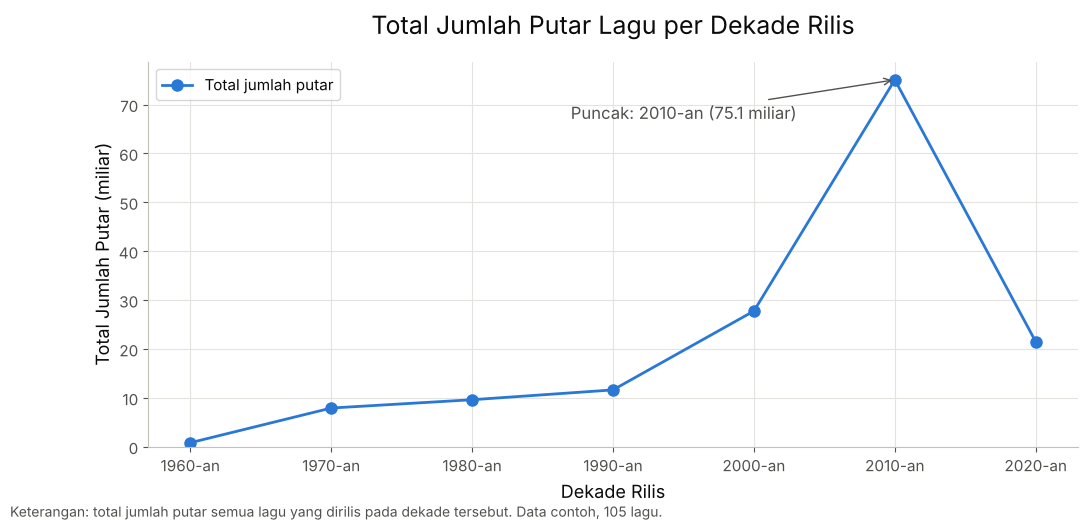

In [ ]:
plt.figure(figsize=(12, 5))

# garis dengan titik, ketebalan 2
plt.plot(agregat_dekade['dekade'], agregat_dekade['jumlah_putar_miliar'],
         color=BIRU, marker='o', markersize=8, linestyle='-', linewidth=2,
         label='Total jumlah putar')

plt.title('Total Jumlah Putar Lagu per Dekade Rilis', loc='center', pad=20, fontsize=18)
plt.xlabel('Dekade Rilis', fontsize=13)
plt.ylabel('Total Jumlah Putar (miliar)', fontsize=13)
plt.grid(color=GARIS_GRID, linestyle='-', linewidth=0.8)
plt.ylim(ymin=0)

# tambah keterangan di titik tertinggi
i_puncak = agregat_dekade['jumlah_putar_miliar'].idxmax()
dekade_puncak = agregat_dekade.loc[i_puncak, 'dekade']
nilai_puncak = agregat_dekade.loc[i_puncak, 'jumlah_putar_miliar']
plt.annotate(f'Puncak: {dekade_puncak} ({nilai_puncak:.1f} miliar)',
             xy=(i_puncak, nilai_puncak), xytext=(i_puncak - 2.3, nilai_puncak - 8),
             color=TEKS_ABU, fontsize=12,
             arrowprops=dict(arrowstyle='->', color=TEKS_ABU))

plt.legend(loc='upper left')
plt.figtext(0.01, -0.03, 'Keterangan: total jumlah putar semua lagu yang dirilis pada dekade tersebut. Data contoh, 105 lagu.',
            fontsize=10, color=TEKS_ABU)
plt.savefig('hasil_visualisasi/01_line_putar_per_dekade.png', dpi=150, bbox_inches='tight')
plt.show()

Interpretasi: Total jumlah putar naik dari 0,8 miliar di 1960-an sampai puncaknya 75,1 miliar di 2010-an, lalu turun jadi 21,5 miliar di 2020-an. Tapi kenaikan ini sebagian besar karena jumlah lagunya memang banyak. Di dataset ini ada 44 lagu dari 2010-an (sekitar 42% data), sedangkan 1960-an cuma 1 lagu. Kalau dirata-rata per lagu, 2010-an sekitar 1,7 miliar dan 2020-an sekitar 1,5 miliar, jadi bedanya tidak sejauh total keseluruhan. Penurunan di 2020-an juga wajar karena lagunya baru 14 dan datanya berhenti di tahun 2023.

### 4.2 Bar Chart: Jumlah Lagu per Genre

Bar chart dipakai untuk membandingkan jumlah antarkategori. Batang dibuat horizontal supaya nama genre mudah dibaca, dan diurutkan dari yang paling banyak.

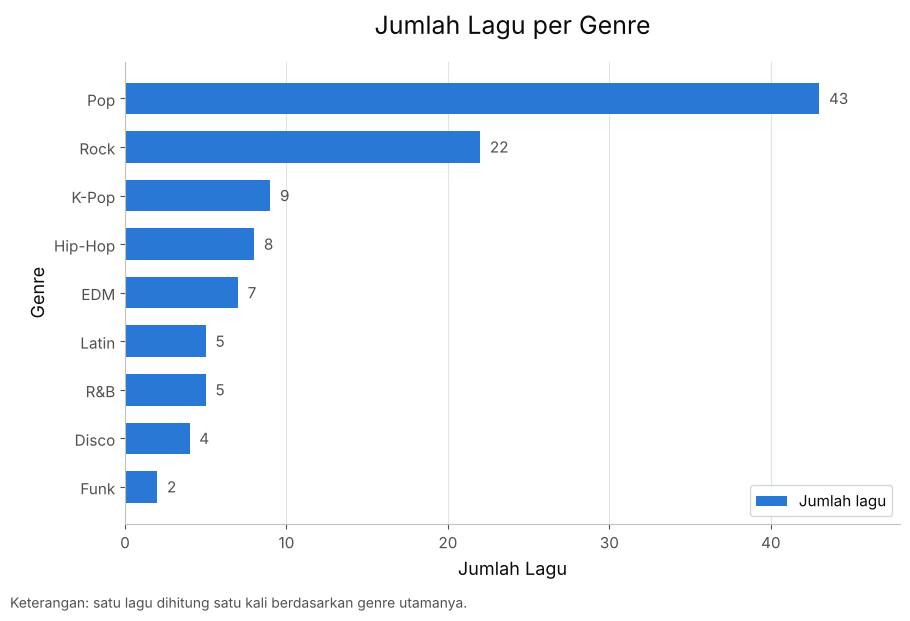

In [ ]:
jumlah_genre = df['genre'].value_counts().sort_values()   # urut naik, supaya yang terbanyak ada di atas

plt.figure(figsize=(10, 6))
plt.barh(jumlah_genre.index, jumlah_genre.values, color=BIRU, height=0.65, label='Jumlah lagu')

# tulis angka di ujung batang
for i, nilai in enumerate(jumlah_genre.values):
    plt.text(nilai + 0.6, i, str(nilai), va='center', color=TEKS_ABU, fontsize=11)

plt.title('Jumlah Lagu per Genre', loc='center', pad=20, fontsize=18)
plt.xlabel('Jumlah Lagu', fontsize=13)
plt.ylabel('Genre', fontsize=13)
plt.xlim(0, jumlah_genre.max() + 5)
plt.grid(axis='x', color=GARIS_GRID, linestyle='-', linewidth=0.8)
plt.gca().set_axisbelow(True)
plt.legend(loc='lower right')
plt.figtext(0.01, -0.03, 'Keterangan: satu lagu dihitung satu kali berdasarkan genre utamanya.', fontsize=10, color=TEKS_ABU)
plt.savefig('hasil_visualisasi/02_bar_jumlah_lagu_per_genre.png', dpi=150, bbox_inches='tight')
plt.show()

Interpretasi: Genre Pop paling banyak dengan 43 lagu (sekitar 41% dari 105 lagu), diikuti Rock dengan 22 lagu. Dua genre ini saja sudah 65 lagu atau sekitar 62% dari seluruh data. Genre lain jumlahnya jauh lebih sedikit, bahkan Disco hanya 4 lagu dan Funk 2 lagu. Artinya dataset ini sangat condong ke Pop dan Rock. Karena itu, di visualisasi berikutnya yang membandingkan genre (boxplot dan rata-rata popularitas), saya hanya memakai genre yang punya minimal 5 lagu supaya perbandingannya masuk akal.

### 4.3 Histogram: Sebaran Skor Popularitas

Histogram dipakai untuk melihat bagaimana nilai sebuah variabel tersebar. Garis tegak menunjukkan rata-rata dan median supaya bentuk sebarannya mudah dibaca.

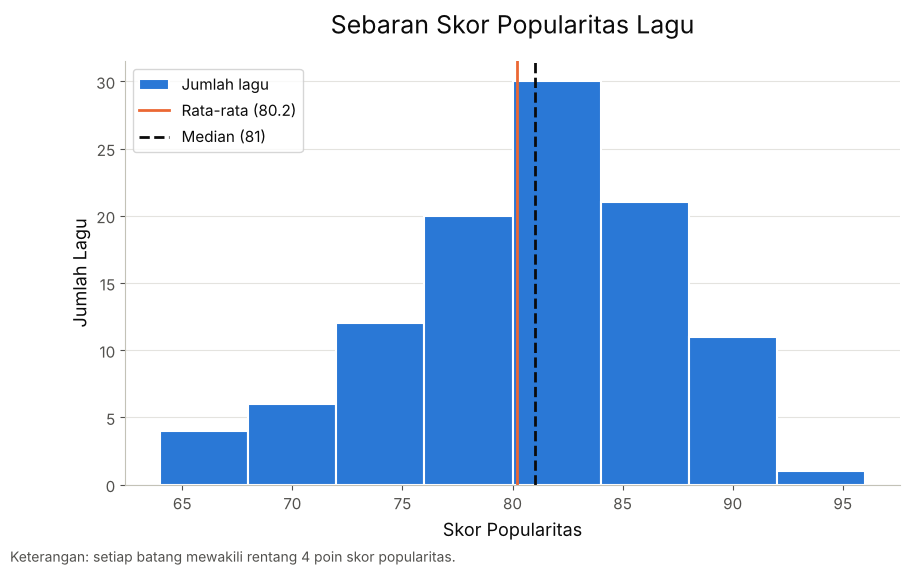

In [ ]:
rata_pop = df['popularitas'].mean()
median_pop = df['popularitas'].median()

plt.figure(figsize=(10, 5.5))
plt.hist(df['popularitas'], bins=np.arange(64, 97, 4), color=BIRU, edgecolor='white', linewidth=1.5,
         label='Jumlah lagu')
plt.axvline(rata_pop, color=ORANYE, linewidth=2, label=f'Rata-rata ({rata_pop:.1f})')
plt.axvline(median_pop, color=TEKS, linewidth=2, linestyle='--', label=f'Median ({median_pop:.0f})')

plt.title('Sebaran Skor Popularitas Lagu', loc='center', pad=20, fontsize=18)
plt.xlabel('Skor Popularitas', fontsize=13)
plt.ylabel('Jumlah Lagu', fontsize=13)
plt.grid(axis='y', color=GARIS_GRID, linestyle='-', linewidth=0.8)
plt.gca().set_axisbelow(True)
plt.legend(loc='upper left')
plt.figtext(0.01, -0.03, 'Keterangan: setiap batang mewakili rentang 4 poin skor popularitas.', fontsize=10, color=TEKS_ABU)
plt.savefig('hasil_visualisasi/03_histogram_popularitas.png', dpi=150, bbox_inches='tight')
plt.show()

Interpretasi: Skor popularitas berkisar dari 65 sampai 92, dengan rata-rata 80,2 dan median 81. Lagu paling banyak ada di rentang 80-83 (30 lagu). Sebarannya sedikit miring ke kiri: rata-rata (80,2) sedikit di bawah median (81), artinya ada beberapa lagu dengan popularitas rendah yang menarik rata-rata ke bawah. Hanya 10 lagu yang skornya di bawah 72, sedangkan 27 lagu punya skor 85 ke atas. Jadi sebagian besar lagu di dataset ini memang lagu yang cukup populer.

### 4.4 Boxplot: Durasi Lagu per Genre

Boxplot dipakai untuk membandingkan sebaran antarkelompok sekaligus melihat outlier. Kotak menunjukkan 50% data di tengah, garis hitam di dalam kotak adalah median, dan titik di luar garis (whisker) adalah outlier. Hanya genre dengan minimal 5 lagu yang dipakai.

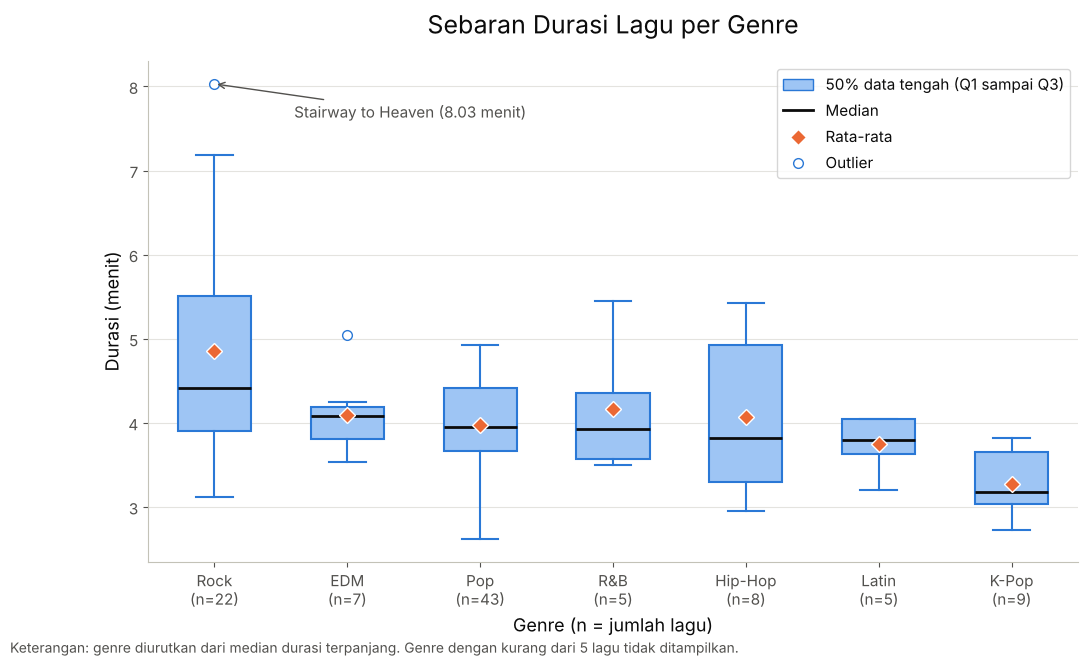

In [ ]:
# genre dengan minimal 5 lagu, diurutkan dari median durasi terpanjang
genre_besar = df['genre'].value_counts()[lambda s: s >= 5].index
urutan = (df[df['genre'].isin(genre_besar)]
          .groupby('genre')['durasi_menit'].median()
          .sort_values(ascending=False).index.tolist())
data_box = [df.loc[df['genre'] == g, 'durasi_menit'] for g in urutan]

plt.figure(figsize=(12, 6.5))
plt.boxplot(data_box, patch_artist=True, showmeans=True, widths=0.55,
            boxprops=dict(facecolor=BIRU_MUDA, edgecolor=BIRU, linewidth=1.5),
            medianprops=dict(color=TEKS, linewidth=2),
            whiskerprops=dict(color=BIRU, linewidth=1.5),
            capprops=dict(color=BIRU, linewidth=1.5),
            flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor=BIRU, markersize=7),
            meanprops=dict(marker='D', markerfacecolor=ORANYE, markeredgecolor='white', markersize=8))
plt.xticks(range(1, len(urutan) + 1), [f'{g}\n(n={len(d)})' for g, d in zip(urutan, data_box)])

# beri nama pada lagu terpanjang (outlier paling jauh)
lagu_terpanjang = df.loc[df['durasi_menit'].idxmax()]
posisi = urutan.index(lagu_terpanjang['genre']) + 1
plt.annotate(f"{lagu_terpanjang['judul']} ({lagu_terpanjang['durasi_menit']:.2f} menit)",
             xy=(posisi, lagu_terpanjang['durasi_menit']),
             xytext=(posisi + 0.6, lagu_terpanjang['durasi_menit'] - 0.4),
             color=TEKS_ABU, fontsize=11, arrowprops=dict(arrowstyle='->', color=TEKS_ABU))

plt.title('Sebaran Durasi Lagu per Genre', loc='center', pad=20, fontsize=18)
plt.xlabel('Genre (n = jumlah lagu)', fontsize=13)
plt.ylabel('Durasi (menit)', fontsize=13)
plt.grid(axis='y', color=GARIS_GRID, linestyle='-', linewidth=0.8)
plt.gca().set_axisbelow(True)

legenda = [Patch(facecolor=BIRU_MUDA, edgecolor=BIRU, label='50% data tengah (Q1 sampai Q3)'),
           Line2D([0], [0], color=TEKS, linewidth=2, label='Median'),
           Line2D([0], [0], marker='D', color='white', markerfacecolor=ORANYE, markersize=8, label='Rata-rata'),
           Line2D([0], [0], marker='o', color='white', markerfacecolor='white', markeredgecolor=BIRU, markersize=7, label='Outlier')]
plt.legend(handles=legenda, loc='upper right')
plt.figtext(0.01, -0.03, 'Keterangan: genre diurutkan dari median durasi terpanjang. Genre dengan kurang dari 5 lagu tidak ditampilkan.',
            fontsize=10, color=TEKS_ABU)
plt.savefig('hasil_visualisasi/04_boxplot_durasi_per_genre.png', dpi=150, bbox_inches='tight')
plt.show()

Interpretasi: Genre Rock punya median durasi paling panjang (4,42 menit) dan sebarannya paling lebar, mulai dari 3,12 sampai 8,03 menit. Sebaliknya K-Pop paling pendek dengan median 3,18 menit dan sebarannya sempit (hanya 2,73 sampai 3,82 menit). Genre lain berada di sekitar 3,8 sampai 4,1 menit. Outlier yang terdeteksi: Stairway to Heaven (Rock, 8:02); Animals (EDM, 5:03). Lagu-lagu ini memang durasinya jauh lebih panjang dari lagu lain di genre yang sama. Durasinya wajar untuk lagu aslinya, jadi tidak saya anggap sebagai data salah.

### 4.5 Scatter Plot: Jumlah Putar vs Popularitas

Scatter plot dipakai untuk melihat hubungan dua variabel numerik. Titik diwarnai berdasarkan asal lagu (lokal atau internasional), dan garis abu-abu adalah garis tren untuk semua lagu.

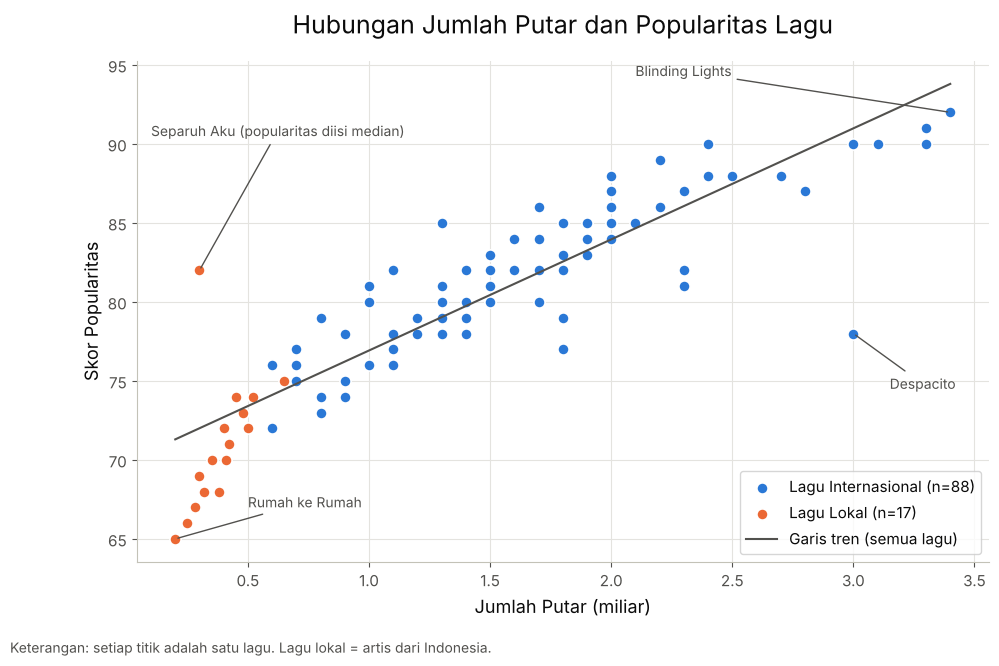

Korelasi semua lagu       : 0.88
Korelasi lagu Internasional: 0.84 | rata-rata putar (miliar): 1.68 | rata-rata popularitas: 82.0
Korelasi lagu Lokal        : 0.53 | rata-rata putar (miliar): 0.38 | rata-rata popularitas: 70.8


In [ ]:
plt.figure(figsize=(11, 6.5))

# gambar titik per kelompok supaya masing-masing punya legenda
for nama, warna in [('Internasional', BIRU), ('Lokal', ORANYE)]:
    d = df[df['asal_lagu'] == nama]
    plt.scatter(d['jumlah_putar_miliar'], d['popularitas'], s=65, color=warna,
                edgecolor='white', linewidth=1.2, label=f'Lagu {nama} (n={len(d)})')

# garis tren (regresi linear sederhana) untuk semua lagu
m, c = np.polyfit(df['jumlah_putar_miliar'], df['popularitas'], 1)
x_garis = np.linspace(df['jumlah_putar_miliar'].min(), df['jumlah_putar_miliar'].max(), 50)
plt.plot(x_garis, m * x_garis + c, color=TEKS_ABU, linewidth=1.5, label='Garis tren (semua lagu)')

# beri nama pada beberapa titik penting saja
df['selisih'] = df['popularitas'] - (m * df['jumlah_putar_miliar'] + c)
terjauh = df.loc[df['selisih'].idxmin()]          # paling jauh di bawah garis tren
tertinggi = df.loc[df['jumlah_putar'].idxmax()]   # paling banyak diputar
terendah = df.loc[df['popularitas'].idxmin()]     # paling rendah popularitasnya
for lagu, geser in [(terjauh, (0.15, -3.5)), (tertinggi, (-1.3, 2.3)), (terendah, (0.3, 2))]:
    plt.annotate(lagu['judul'], xy=(lagu['jumlah_putar_miliar'], lagu['popularitas']),
                 xytext=(lagu['jumlah_putar_miliar'] + geser[0], lagu['popularitas'] + geser[1]),
                 color=TEKS_ABU, fontsize=10, arrowprops=dict(arrowstyle='-', color=TEKS_ABU))

# satu lagu lokal terlihat menyimpang karena popularitasnya hasil pengisian median (nilai aslinya kosong)
sm = df[df['judul'] == 'Separuh Aku'].iloc[0]
plt.annotate('Separuh Aku (popularitas diisi median)', xy=(sm['jumlah_putar_miliar'], sm['popularitas']),
             xytext=(0.1, 90.5), color=TEKS_ABU, fontsize=10, arrowprops=dict(arrowstyle='-', color=TEKS_ABU))

plt.title('Hubungan Jumlah Putar dan Popularitas Lagu', loc='center', pad=20, fontsize=18)
plt.xlabel('Jumlah Putar (miliar)', fontsize=13)
plt.ylabel('Skor Popularitas', fontsize=13)
plt.grid(color=GARIS_GRID, linestyle='-', linewidth=0.8)
plt.gca().set_axisbelow(True)
plt.legend(loc='lower right')
plt.figtext(0.01, -0.03, 'Keterangan: setiap titik adalah satu lagu. Lagu lokal = artis dari Indonesia.', fontsize=10, color=TEKS_ABU)
plt.savefig('hasil_visualisasi/05_scatter_putar_vs_popularitas.png', dpi=150, bbox_inches='tight')
plt.show()

print('Korelasi semua lagu       :', round(df['jumlah_putar_miliar'].corr(df['popularitas']), 2))
for nama in ['Internasional', 'Lokal']:
    d = df[df['asal_lagu'] == nama]
    print(f'Korelasi lagu {nama:<13}:', round(d['jumlah_putar_miliar'].corr(d['popularitas']), 2),
          '| rata-rata putar (miliar):', round(d['jumlah_putar_miliar'].mean(), 2),
          '| rata-rata popularitas:', round(d['popularitas'].mean(), 1))

Interpretasi: Titik-titik membentuk pola naik dari kiri bawah ke kanan atas, artinya lagu yang lebih banyak diputar cenderung punya skor popularitas lebih tinggi. Korelasinya kuat, yaitu 0,88 untuk semua lagu (0,84 pada lagu internasional dan 0,53 pada lagu lokal). Lagu lokal (17 lagu) mengumpul di kiri bawah: rata-rata diputar 0,38 miliar dengan popularitas 70,8, sedangkan lagu internasional (88 lagu) rata-rata 1,68 miliar dengan popularitas 82,0. Satu lagu lokal, Separuh Aku, terlihat menyimpang ke atas (popularitas 82) karena skornya hasil pengisian median saat Data Cleansing, bukan nilai asli. Ada juga lagu yang berada jauh di bawah garis tren, yaitu Despacito (diputar 3,0 miliar kali tapi popularitasnya hanya 78), yang artinya jumlah putar yang besar belum tentu selalu diikuti skor popularitas yang tinggi. Perlu diingat ini hanya hubungan antarvariabel, bukan bukti sebab-akibat.

### 4.6 Heatmap: Korelasi Antarvariabel Numerik

Heatmap dipakai untuk melihat sekaligus hubungan antar beberapa variabel. Nilai korelasi berkisar -1 sampai 1. Warna biru berarti hubungan searah (positif), merah berarti berlawanan (negatif), dan abu-abu berarti hampir tidak ada hubungan.

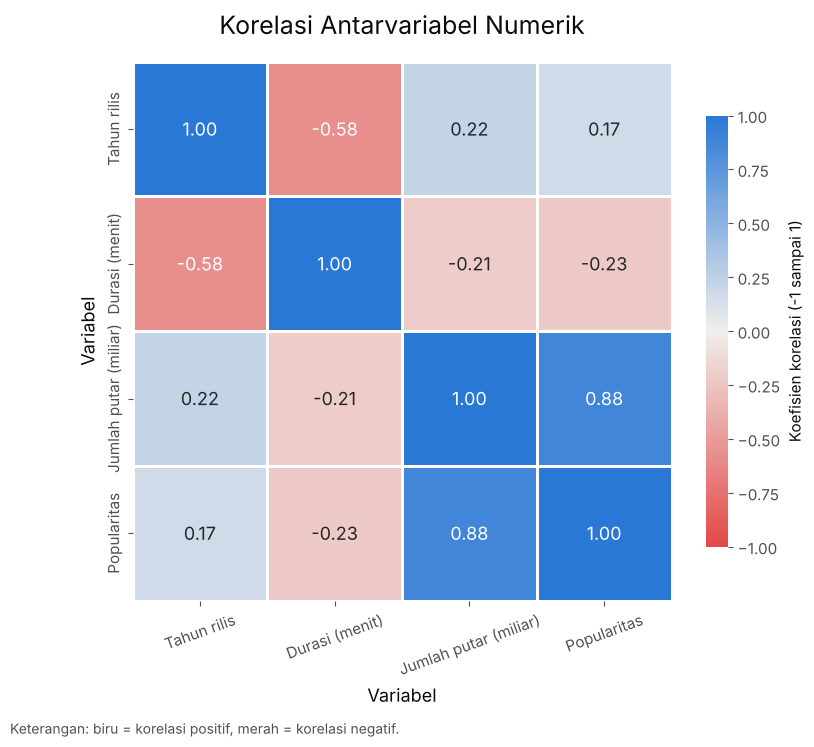

In [ ]:
kolom_korelasi = ['tahun_rilis', 'durasi_menit', 'jumlah_putar_miliar', 'popularitas']
nama_tampil = ['Tahun rilis', 'Durasi (menit)', 'Jumlah putar (miliar)', 'Popularitas']
korelasi = df[kolom_korelasi].corr()
korelasi.index = nama_tampil
korelasi.columns = nama_tampil

# warna: biru (positif) - abu-abu (nol) - merah (negatif)
warna_korelasi = LinearSegmentedColormap.from_list('biru_abu_merah', ['#e34948', '#f0efec', '#2a78d6'])

plt.figure(figsize=(9, 7))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap=warna_korelasi, vmin=-1, vmax=1,
            linewidths=2, linecolor='white', square=True, annot_kws={'size': 13},
            cbar_kws={'label': 'Koefisien korelasi (-1 sampai 1)', 'shrink': 0.8})
plt.title('Korelasi Antarvariabel Numerik', loc='center', pad=20, fontsize=18)
plt.xlabel('Variabel', fontsize=13)
plt.ylabel('Variabel', fontsize=13)
plt.xticks(rotation=20)
plt.figtext(0.01, -0.08, 'Keterangan: biru = korelasi positif, merah = korelasi negatif.', fontsize=10, color=TEKS_ABU)
plt.savefig('hasil_visualisasi/06_heatmap_korelasi.png', dpi=150, bbox_inches='tight')
plt.show()

Interpretasi: Hubungan paling kuat ada antara jumlah putar dan popularitas (0,88), sama dengan yang terlihat di scatter plot. Hubungan kuat kedua adalah tahun rilis dan durasi (-0,58, negatif): makin baru tahun rilisnya, durasi lagu cenderung makin pendek. Ini cocok dengan temuan di boxplot: dari 10 lagu terpanjang di dataset, 8 dirilis sebelum tahun 2000, misalnya Stairway to Heaven (1971), Hey Jude (1968), Hotel California (1976). Variabel lain hubungannya lemah: tahun rilis dengan popularitas 0,17, tahun rilis dengan jumlah putar 0,22, dan durasi dengan popularitas -0,23. Jadi tahun rilis dan durasi hampir tidak menentukan seberapa populer sebuah lagu di dataset ini.

### 4.7 Bar Chart: Rata-rata Popularitas per Genre

Bar chart kedua ini membandingkan rata-rata popularitas antargenre (hanya genre dengan minimal 5 lagu). Genre dengan rata-rata tertinggi diberi warna biru, genre lain abu-abu supaya yang menonjol langsung kelihatan. Sumbu mulai dari 0 supaya perbedaannya tidak terlihat dilebih-lebihkan.

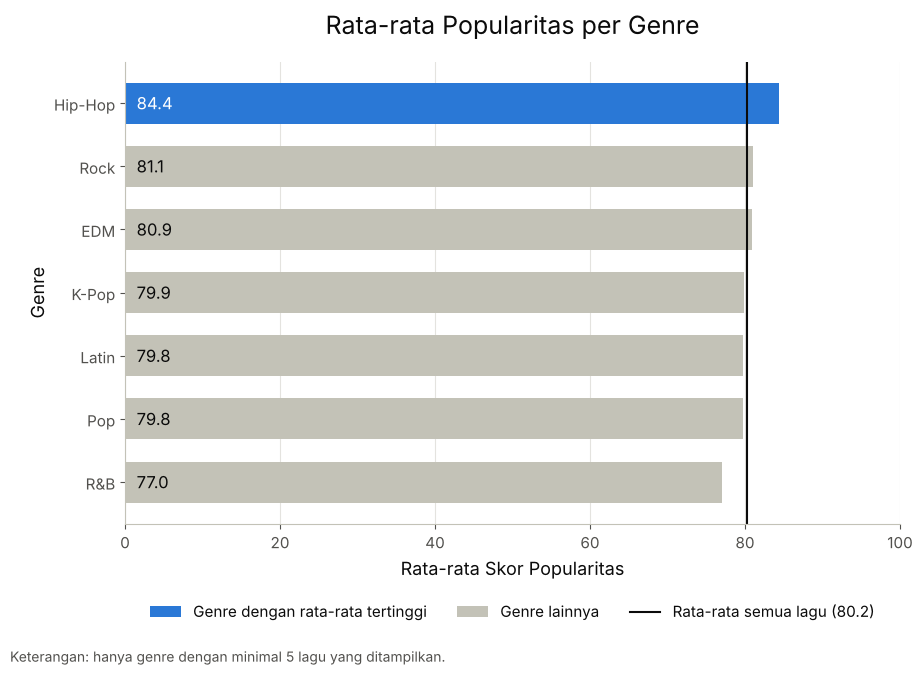

In [ ]:
rata_genre = (df[df['genre'].isin(genre_besar)]
              .groupby('genre')['popularitas'].mean().sort_values())
rata_semua = df['popularitas'].mean()

# genre tertinggi biru, sisanya abu-abu
warna_batang = [BIRU if g == rata_genre.idxmax() else ABU for g in rata_genre.index]

plt.figure(figsize=(10, 6))
plt.barh(rata_genre.index, rata_genre.values, color=warna_batang, height=0.65)
plt.axvline(rata_semua, color=TEKS, linewidth=1.5)

# angka ditulis di dalam batang (sisi kiri) supaya tidak bertabrakan dengan garis rata-rata
for i, (g, nilai) in enumerate(rata_genre.items()):
    plt.text(1.5, i, f'{nilai:.1f}', va='center', ha='left', fontsize=12,
             color='white' if g == rata_genre.idxmax() else TEKS)

plt.title('Rata-rata Popularitas per Genre', loc='center', pad=20, fontsize=18)
plt.xlabel('Rata-rata Skor Popularitas', fontsize=13)
plt.ylabel('Genre', fontsize=13)
plt.xlim(0, 100)
plt.grid(axis='x', color=GARIS_GRID, linestyle='-', linewidth=0.8)
plt.gca().set_axisbelow(True)

legenda = [Patch(facecolor=BIRU, label='Genre dengan rata-rata tertinggi'),
           Patch(facecolor=ABU, label='Genre lainnya'),
           Line2D([0], [0], color=TEKS, linewidth=1.5, label=f'Rata-rata semua lagu ({rata_semua:.1f})')]
plt.legend(handles=legenda, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
plt.figtext(0.01, -0.12, 'Keterangan: hanya genre dengan minimal 5 lagu yang ditampilkan.', fontsize=10, color=TEKS_ABU)
plt.savefig('hasil_visualisasi/07_bar_rata_popularitas_per_genre.png', dpi=150, bbox_inches='tight')
plt.show()

Interpretasi: Genre Hip-Hop punya rata-rata popularitas tertinggi (84,4), dan R&B terendah (77,0). Selisih keduanya hanya 7,4 poin, dan sebagian besar genre berada dekat rata-rata semua lagu (80,2). Jadi genre bukan pembeda yang besar untuk popularitas di dataset ini. Hasil Hip-Hop juga perlu dibaca hati-hati karena jumlah lagunya cuma 8, sehingga satu atau dua lagu saja bisa mengubah rata-ratanya.

## 5. Ringkasan Insight

| No | Visualisasi | Insight utama |
|---|---|---|
| 1 | Line chart | Total jumlah putar tertinggi ada di dekade 2010-an (75,1 miliar), terutama karena jumlah lagunya paling banyak (44 lagu) |
| 2 | Bar chart genre | Pop paling banyak (43 lagu), disusul Rock (22 lagu), dataset condong ke dua genre ini |
| 3 | Histogram | Popularitas rata-rata 80,2 dan median 81, sebaran sedikit miring ke kiri |
| 4 | Boxplot | Rock paling panjang dan paling bervariasi, K-Pop paling pendek, outlier: Stairway to Heaven (Rock, 8:02); Animals (EDM, 5:03) |
| 5 | Scatter plot | Jumlah putar dan popularitas berkorelasi kuat (0,88), lagu lokal lebih rendah dari internasional |
| 6 | Heatmap | Lagu yang lebih baru cenderung lebih pendek (korelasi -0,58) |
| 7 | Bar chart popularitas | Perbedaan rata-rata popularitas antargenre kecil (selisih 7,4 poin) |

## 6. Kesimpulan

Pada project ini saya memvisualisasikan dataset 105 lagu memakai Matplotlib dan Seaborn dengan 7 teknik visualisasi: line chart, bar chart (dua kali), histogram, boxplot, scatter plot, dan heatmap. Sebelumnya data ditambah beberapa kolom baru dan diagregasi per dekade, sesuai langkah yang diajarkan di materi.

Dari hasil visualisasi, ada beberapa temuan utama:

1. Dataset didominasi genre Pop (43 lagu) dan Rock (22 lagu), dan lagu dari dekade 2010-an paling banyak (44 lagu).
2. Skor popularitas rata-rata 80,2 dengan median 81, jadi sebagian besar lagu di dataset ini tergolong populer.
3. Jumlah putar dan popularitas punya hubungan yang kuat (korelasi 0,88). Lagu internasional rata-rata lebih banyak diputar dan lebih populer daripada lagu lokal.
4. Durasi lagu cenderung makin pendek pada lagu yang lebih baru (korelasi -0,58). Lagu Rock paling panjang dan punya outlier, sedangkan K-Pop paling pendek.
5. Genre tidak banyak membedakan popularitas, karena selisih rata-rata antargenre hanya 7,4 poin.

Perlu diingat bahwa dataset ini hanya berisi 105 lagu dengan nilai contoh yang saya susun sendiri, jadi temuan di atas hanya gambaran untuk latihan dan belum tentu berlaku untuk industri musik secara umum. Dari tugas ini saya belajar bahwa jenis grafik harus dipilih sesuai tujuan: line chart untuk tren, histogram dan boxplot untuk sebaran, scatter plot dan heatmap untuk hubungan antarvariabel, serta bar chart untuk perbandingan antarkategori.

## 7. Menyimpan Hasil

Semua grafik sudah disimpan otomatis ke folder hasil_visualisasi saat dijalankan. Berikut daftar filenya.

In [ ]:
for nama_file in sorted(os.listdir('hasil_visualisasi')):
    print(nama_file)

01_line_putar_per_dekade.png
02_bar_jumlah_lagu_per_genre.png
03_histogram_popularitas.png
04_boxplot_durasi_per_genre.png
05_scatter_putar_vs_popularitas.png
06_heatmap_korelasi.png
07_bar_rata_popularitas_per_genre.png
